# Prototype De-stacking

In [1]:
import numpy as np
from matplotlib import pyplot as plt

import glob
import tqdm

#let's use multiprocessing
from multiprocess import Pool, freeze_support, cpu_count
from functools import partial

from colossus.halo import profile_nfw
from colossus.cosmology import cosmology as colossus_cosmology

from scipy import integrate
from scipy.stats import truncnorm
from scipy.stats import norm,multivariate_normal

from nautilus import Prior
from nautilus import Sampler

from astropy.cosmology import FlatLambdaCDM, Planck18 
import astropy.units as u
from astropy import constants
from astropy import table
import galsim

import xlensing
import cluster_toolkit

Lookup table loaded!


In [2]:
datadir = "/home/andre/data/TNG_SIMULATED_SHEAR_CATALOGS"

## Defining Units and scalings between codes

In [236]:
Mhalo = 1e14
conc = 5.
zhalo = .3
zsource = 1.0
OmegaM = 0.3
OmegaL = 0.7
astropy_cosmo = Planck18#FlatLambdaCDM(H0=.7,Om0=OmegaM)
galsim_cosmo = galsim.Cosmology()
halo = galsim.NFWHalo(mass=Mhalo,conc=conc,redshift=zhalo,cosmo=galsim_cosmo)

In [237]:
radii_mpc = np.linspace(0.01,10,1000)
ang_radii = np.degrees(radii_mpc/astropy_cosmo.angular_diameter_distance(.3).value)*3600
positions = [galsim.PositionD(0.,sep) for sep in ang_radii]

In [238]:
shears_galsim = np.array([halo.getShear(position,zsource) for position in positions])

In [239]:
def critical_surface_density(z_l, z_s, cosmo):
    """
    Calculates the critical surface density for gravitational lensing.

    Args:
        z_l (float): Redshift of the lensing galaxy.
        z_s (float): Redshift of the background source.
        cosmo (astropy.cosmology.Cosmology): The cosmological model to use.

    Returns:
        astropy.units.Quantity: The critical surface density.
    """
    # Define angular diameter distances
    D_l = cosmo.angular_diameter_distance(z_l)
    D_s = cosmo.angular_diameter_distance(z_s)
    D_ls = cosmo.angular_diameter_distance_z1z2(z_l, z_s)

    # Formula for the critical surface density
    numerator = (constants.c**2 * D_s)
    denominator = (4 * np.pi * constants.G * D_l * D_ls)
    sigma_crit = numerator / denominator

    # Convert to standard units for surface density (e.g., Msun / sq pc)
    return sigma_crit.to(u.M_sun / u.kpc**2)


# Define the redshifts for the lens and source
z_lens = 0.5   # Example lens redshift
z_source = 2.0 # Example source redshift

# Calculate the critical surface density
sigma_crit_value = critical_surface_density(z_lens, z_source, astropy_cosmo)

print(f"Lens redshift: {z_lens}")
print(f"Source redshift: {z_source}")
print(f"Critical surface density: {sigma_crit_value:.2e}")

# Example comparison: what if the lens is closer?
z_lens_closer = 0.25
sigma_crit_closer = critical_surface_density(z_lens_closer, z_source, astropy_cosmo)

print("\n--- Example with a closer lens ---")
print(f"Lens redshift: {z_lens_closer}")
print(f"Critical surface density: {sigma_crit_closer:.2e}")

Lens redshift: 0.5
Source redshift: 2.0
Critical surface density: 2.02e+09 solMass / kpc2

--- Example with a closer lens ---
Lens redshift: 0.25
Critical surface density: 2.48e+09 solMass / kpc2


In [240]:
def deltasigma_nfw_colossus(colossus_profile,z_source,r):
    z_lens = zhalo
    Sigma_bar = 2*(integrate.quad(lambda r : colossus_profile.surfaceDensity(r)*r,1e-8,r,epsabs=0.,limit=150))[0]/r**2
    Sigma = colossus_profile.surfaceDensity(r)
    deltasigma = Sigma_bar - Sigma
    return deltasigma/1e6

In [241]:
scrit=critical_surface_density(z_l=0.3, z_s=1.0, cosmo=astropy_cosmo).value/1e6

In [242]:
colossus_cosmology.setCosmology('planck18')
colossus_profile=profile_nfw.NFWProfile(M=Mhalo,c=conc,z=zhalo,mdef='200m')
delta_sigma_colossus=np.array([deltasigma_nfw_colossus(colossus_profile,1.,radius*1000) for radius in radii_mpc])

In [243]:
from cluster_toolkit import deltasigma

Sigma_nfw = deltasigma.Sigma_nfw_at_R(radii_mpc, mass=Mhalo, concentration=conc, Omega_m=OmegaM)
#shears_toolkit = deltasigma.DeltaSigma_at_R(radii_mpc, Rp, Sigma, Mass, concentartion, Omega_m)
delta_sigma_toolkit=deltasigma.DeltaSigma_at_R(
    R=radii_mpc,
    Rs=radii_mpc,
    Sigma=Sigma_nfw,
    mass=Mhalo,
    concentration=conc,
    Omega_m=OmegaM,
    delta=200,
)

In [244]:
xlensing_res=NFW_shear(Mhalo,conc,zhalo,1.,0.,0.,radii_mpc)
delta_sigma_xlensing = xlensing_res['NFW Signal']

In [245]:
delta_sigma_galsim = shears_galsim[:,0]*scrit

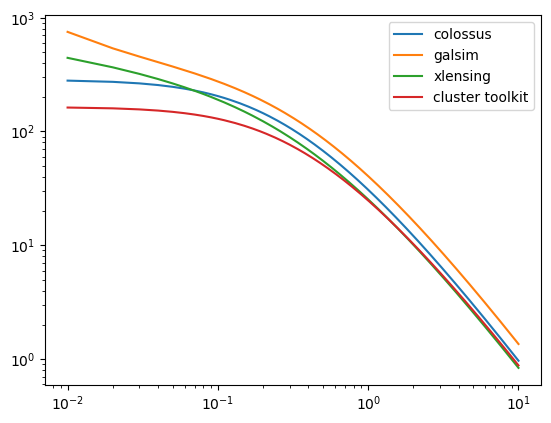

In [255]:
plt.plot(radii_mpc,delta_sigma_colossus,label='colossus')
plt.plot(radii_mpc,delta_sigma_galsim,label='galsim')
plt.plot(radii_mpc,delta_sigma_xlensing*cosmo.h**2,label='xlensing')
plt.plot(radii_mpc,delta_sigma_toolkit,label='cluster toolkit')

plt.xscale('log')
plt.yscale('log')
plt.legend()

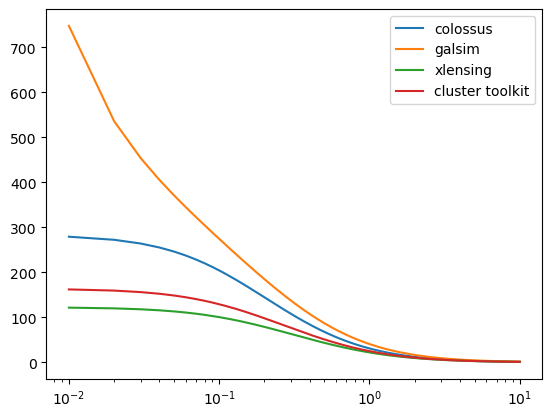

In [14]:
plt.plot(radii_mpc,delta_sigma_colossus,label='colossus')
plt.plot(radii_mpc,delta_sigma_galsim,label='galsim')
plt.plot(radii_mpc,delta_sigma_xlensing,label='xlensing')
plt.plot(radii_mpc,delta_sigma_toolkit,label='cluster toolkit')

plt.xscale('log')
#plt.yscale('log')
plt.legend()

In [15]:
radii_mpc = np.logspace(-2,1,10)

In [16]:
%%timeit
colossus_profile=profile_nfw.NFWProfile(M=Mhalo,c=conc,z=zhalo,mdef='200m')
delta_sigma_colossus=np.array([deltasigma_nfw_colossus(colossus_profile,1.,radius*1000) for radius in radii_mpc])

33.3 ms ± 1.43 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [17]:
%%timeit
halo = galsim.NFWHalo(mass=Mhalo,conc=conc,redshift=zhalo,cosmo=galsim_cosmo)
shears_galsim = np.array([halo.getShear(position,zsource) for position in positions])

72.8 ms ± 4.07 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [18]:
%%timeit
xlensing_res=xlensing.model.NFW_shear(Mhalo,conc,zhalo,1.,0.,0.,radii_mpc)

6.22 ms ± 164 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [19]:
%%timeit
Sigma_nfw = deltasigma.Sigma_nfw_at_R(radii_mpc, mass=Mhalo, concentration=conc, Omega_m=OmegaM)
#shears_toolkit = deltasigma.DeltaSigma_at_R(radii_mpc, Rp, Sigma, Mass, concentartion, Omega_m)
delta_sigma_toolkit=deltasigma.DeltaSigma_at_R(R=radii_mpc,Rs=radii_mpc,Sigma=Sigma_nfw,mass=Mhalo,concentration=conc,Omega_m=OmegaM,delta=200,
)

21.6 μs ± 1e+03 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## Generating a field of galaxies

In [20]:
n_gal_factor = 100
max_radius = 8
nbar = 30 
cluster = [0.,0.,.3,1e14,5.] 

In [21]:
def simcluster(gal_density,total_radius,z_range,cluster,shape_noise,seed=31415):
    cat = xlensing.sims.make_simple_random_cat(
        density=gal_density, 
        width_rad=total_radius/xlensing.cosmo.DA(0,0.3), 
        zrange=z_range, 
        shape_noise=shape_noise,
        seed=seed
    ).T
    cat = xlensing.sims.apply_NFW_shear_region(cluster,cat)
    cat = table.Table(cat,names=['ra','dec','z','e1','e2','R11','R12','R21','R22','w'])
    return cat 

In [22]:
cluster_test = simcluster(gal_density=nbar,total_radius=max_radius,z_range=[.3,2.],cluster=cluster,shape_noise=0.25/np.sqrt(n_gal_factor),seed=None)

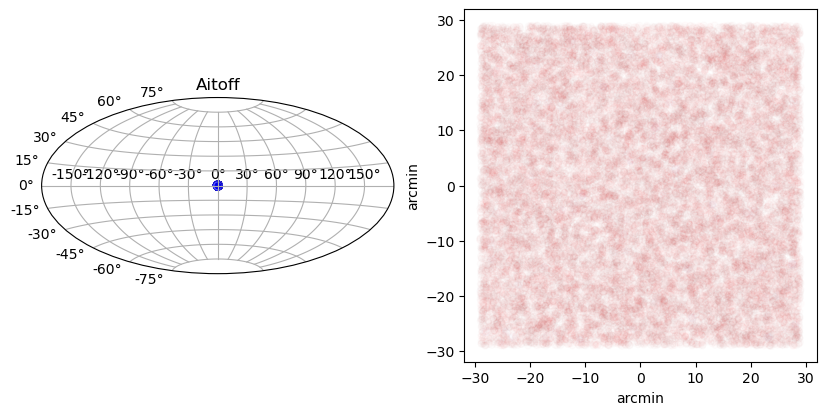

In [23]:
plt.figure(figsize=(10,5))
plt.subplot(121, projection="aitoff")
ellip = np.sqrt(cluster_test['e1']**2+ cluster_test['e2']**2)
plt.scatter(cluster_test['ra'],cluster_test['dec'],s=(cluster_test['z']+1)*10,c=ellip,cmap='seismic')
plt.title("Aitoff")
plt.grid(True)
plt.subplot(122)
plt.scatter(np.degrees(cluster_test['ra'])*60,np.degrees(cluster_test['dec'])*60,s=(cluster_test['z']+1)*10,c=np.log10(ellip),cmap='seismic',alpha=.01)
plt.xlabel('arcmin')
plt.ylabel('arcmin')
ax = plt.gca()
ax.set_aspect('equal')

In [24]:
galaxy_catalog = {}
galaxy_catalog['RA'] = cluster_test['ra']
galaxy_catalog['DEC'] = cluster_test['dec']
galaxy_catalog['ZPHOT'] = cluster_test['z']
galaxy_catalog['E1'] = cluster_test['e1']
galaxy_catalog['E2'] = cluster_test['e2']
galaxy_catalog['WEIGHT'] =  np.ones_like(cluster_test['e1'])
galaxy_catalog['M'] = np.zeros_like(cluster_test['e1'])
galaxy_catalog = table.Table(galaxy_catalog)

## Fitting

In [25]:
clusters = table.Table([[0],[0],[0.3]],names=['RA','DEC', 'Z'])

In [26]:
sr_RA = np.array(galaxy_catalog['RA'])
sr_DEC= np.array(galaxy_catalog['DEC'])
sr_z  = np.array(galaxy_catalog['ZPHOT'])
sr_E1 = np.array(galaxy_catalog['E1'])
sr_E2 = np.array(galaxy_catalog['E2'])
sr_W = np.array(galaxy_catalog['WEIGHT'])
sr_M = np.array(galaxy_catalog['M'])

clusters['INDEX'] = np.array(range(len(clusters)))

In [27]:
galaxy_catalog

RA,DEC,ZPHOT,E1,E2,WEIGHT,M
float64,float64,float64,float64,float64,float64,float64
-0.00260712208680875,0.0037838603378218903,0.9115579371302083,0.010240307611777971,-0.011350964702734983,1.0,0.0
0.00581078272232839,-0.0028275977167868576,1.692115542617567,0.031554283914472306,0.009615418202414076,1.0,0.0
0.00502488089120879,-0.005020943677002828,1.425663917958858,-0.024158236277921262,-0.01829208329163708,1.0,0.0
-0.004506155491649016,0.0020045022591935763,1.0195430540894235,-0.028832652060251398,0.005839919158555425,1.0,0.0
0.006782371996435645,-0.003734163526085286,1.964044063116803,-0.037959987523944846,-0.03377015292432617,1.0,0.0
0.0025342435135024127,-0.005874158381731035,1.2997707749607692,0.04233803625418998,0.004210748503055761,1.0,0.0
-0.00804291600301719,-0.003881350789695064,1.5585054886858893,-0.014897098528598735,0.03131350934140016,1.0,0.0
0.002830018151615623,-5.212764130686949e-05,0.37789685933397704,0.0367256529855178,0.020263073413866014,1.0,0.0
-0.0009462866740089625,0.003739458573738594,1.9409220841945378,0.00460889681885459,-0.02302480040257552,1.0,0.0


In [28]:
cl_RA=np.array(clusters['RA'])
cl_DEC= np.array(clusters['DEC'])
cl_z= np.array(clusters['Z'])
cl = np.array([cl_RA,cl_DEC,cl_z]).T

In [29]:


# you can use whatever, but your machine core count is usually a good choice (although maybe not the best)
pool = Pool(cpu_count()) 

#We get a partial function with a constant galaxy catalogue to iterate with clusters.
survey_lensing = partial(
    xlensing.data.lensfit_cluster_lensing,
    sources=(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M),
    radius=10.
)

In [30]:
clz = zip(cl_RA,cl_DEC,cl_z)
clzlist = [x for x in clz]

In [31]:
results = pool.map(survey_lensing, clzlist)
pool.close()

## Stacking

In [32]:
radii = np.logspace(-.6,.6,8)
N = len(radii)
bins_lims = np.logspace(np.log10(radii[0])+(np.log10(radii[0])-np.log10(radii[1]))/2,
                        np.log10(radii[N-1])-(np.log10(radii[0])-np.log10(radii[1]))/2,N+1)
bins_lims = np.array([[bins_lims[i],bins_lims[i+1]] for i in range(N)])
bins_lims #in Mpc/h

array([[0.2061986 , 0.30599497],
       [0.30599497, 0.45409096],
       [0.45409096, 0.67386272],
       [0.67386272, 1.        ],
       [1.        , 1.48398179],
       [1.48398179, 2.20220195],
       [2.20220195, 3.26802759],
       [3.26802759, 4.84969343]])

In [33]:
stick = [clusters]

In [34]:
Nboot=1000
import time
stick_results = []
for stake in stick:
    t = time.time()
    clusterbkgs = []
    for index in range(1):
        Sigma_crit = np.array(results[0]['Critical Density'])
        e_t = np.array(results[0]['Tangential Shear'])
        e_x = np.array(results[0]['Critical Density'])
        W = np.array(results[0]['Weights'])
        M = np.array(results[0]['Mult. Bias'])
        R = np.array(results[0]['Radial Distance'])
        clusterbkgs.append(np.array([Sigma_crit, e_t, e_x, W, R,M]))
    print(len(clusterbkgs))
    #sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.stack(clusterbkgs,bins_lims,Nboot)
    #stick_results.append( ( sigmas, sigmas_cov, xigmas, xigmas_cov) )
    #print("Done in " + str(time.time()-t) + " seconds.")

1


In [35]:
sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.single_cluster([clusterbkgs[0]],bins_lims,Nboot)

Total galaxies available per bin:
[16, 34, 61, 173, 327, 744, 1678, 3635]

Single cluster:
Separating galaxies per radial bin...


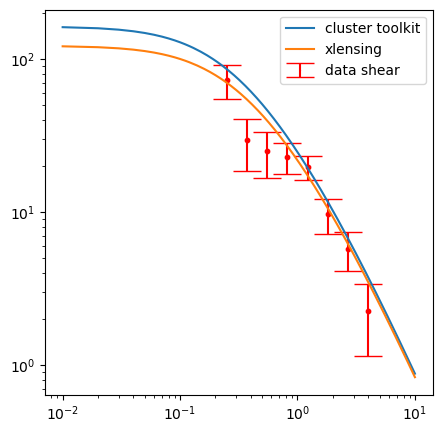

In [36]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas),color='red',s=10)
plt.errorbar(radii,np.array(sigmas),
             yerr=np.sqrt(np.diag(sigmas_cov)),
             fmt='.',color='red',markersize=.1,capsize=10,label='data shear')
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')
radii_mpc = np.linspace(0.01,10,1000)
plt.plot(radii_mpc,delta_sigma_toolkit,label='cluster toolkit')
plt.plot(radii_mpc,delta_sigma_xlensing,label='xlensing')
plt.legend()
plt.savefig("1clustertest.png")

# Fitting a single cluster

In [37]:
from scipy.stats import truncnorm


loc = 5
a_trunc = .1
b_trunc = 10
scale = 4
a, b = (a_trunc - loc) / scale, (b_trunc - loc) / scale
prior_c= truncnorm(a=a,b=b,loc=loc,scale=scale)


prior = Prior()
prior.add_parameter('logMhalo', dist=norm(12,4))



prior.add_parameter('conc', dist=prior_c)

In [38]:
def model_wrapper(param_dict):
    delta_sigma_model=xlensing.model.NFW_shear(
        10**param_dict['logMhalo'],
        param_dict['conc'],
        zhalo,
        1.,
        0.,
        0.,
        radii
    )['NFW Signal']

    return delta_sigma_model

In [39]:




def loglike(param_dict):
    model=model_wrapper(param_dict)
    data=sigmas
    return multivariate_normal.logpdf(model-data,cov=sigmas_cov)
    

In [40]:
param_test = {
    'logMhalo': 14,
    'conc': 5,   
}
model_wrapper(param_test)

array([69.97083208, 54.36091931, 39.56197263, 27.01160184, 17.39228288,
       10.63781847,  6.22950287,  3.51879972])

In [41]:
sampler = Sampler(prior, loglike, n_live=1000,pool=15)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 14     | 1        | 4        | 18900    | N/A    | 10092 | -27.48   


np.True_

In [42]:
points, log_w, log_l = sampler.posterior()
mlo, mmd, mhi = np.percentile(points[:,0],[16,50,84])
clo, cmd, chi = np.percentile(points[:,1],[16,50,84])

print("Marginalized:")
print(f"logMass: {mmd:.4f} - {mmd-mlo:.4f} + {mhi-mmd:.4f}")
print(f"conc: {cmd:.4f} - {cmd-clo:.4f} + {chi-cmd:.4f}")

Marginalized:
logMass: 13.9017 - 0.6306 + 0.0605
conc: 3.9162 - 0.9158 + 2.1656


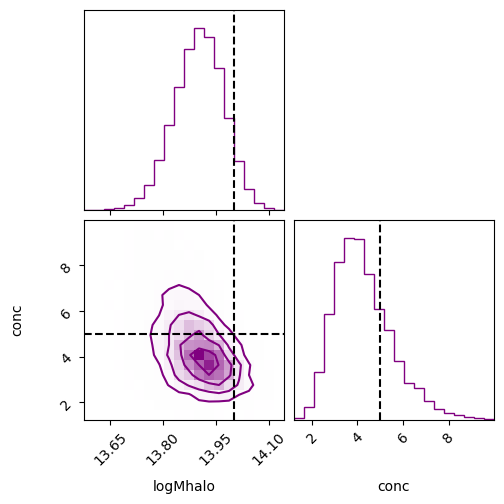

In [43]:
import corner



figure = corner.corner(
    points, weights=np.exp(log_w), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.9999, len(prior.keys)))


corner.overplot_lines(figure, [14,5], color="black", linestyle="--")

In [44]:
curve_samples = []
for index in tqdm.tqdm(range(300)):
    point = points[np.random.randint(0,len(points)-1)]
    xlensing_res=xlensing.model.NFW_shear(10**point[0],point[1],zhalo,1.,0.,0.,radii_mpc)
    delta_sigma_data = xlensing_res['NFW Signal']
    curve_samples += [delta_sigma_data]

100%|█████████████████████████████████████████████████████████████████████████████████| 300/300 [00:20<00:00, 14.57it/s]


In [45]:
xlensing_true=xlensing.model.NFW_shear(Mhalo,conc,zhalo,1.,0.,0.,radii_mpc)
delta_sigma_true = xlensing_true['NFW Signal']

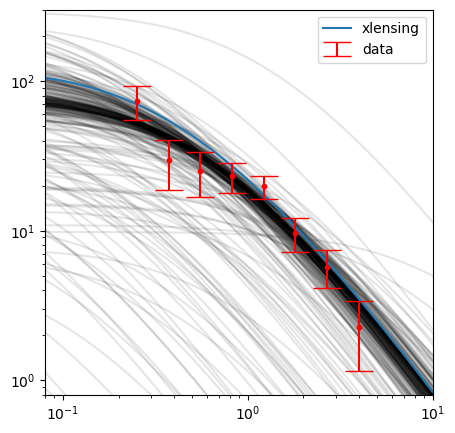

In [46]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas),color='red',s=10,zorder=3)
plt.errorbar(radii,np.array(sigmas),
             yerr=np.sqrt(np.diag(sigmas_cov)),
             fmt='.',color='red',markersize=.1,capsize=10,label='data',zorder=3)
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')

plt.xlim([.8e-1,1e1])
plt.ylim([8e-1,3e2])
for curve_sample in curve_samples:
    plt.plot(radii_mpc,curve_sample,alpha=.1,color='black')


plt.plot(radii_mpc,delta_sigma_true,label='xlensing')
plt.legend()
plt.savefig("1clustertest.png")

# Is it biased?

In [47]:
def make_clusters(n):
    zcluster=np.random.uniform(0.25,0.35)
    cluster_params = [0.,0.,zcluster,np.random.uniform(.9e14,1.1e14),np.random.uniform(4.5,5.5)]
    cluster = simcluster(gal_density=30,total_radius=5,z_range=[zcluster,2.],cluster=cluster_params,shape_noise=0.25,seed=None)
    return {'cluster': cluster, 'cluster_params':cluster_params}

In [48]:
clusters= np.load("clusters.npy",allow_pickle=True)
cluster_params= np.load("cluster_params.npy",allow_pickle=True)

In [49]:
galaxy_catalogs = []

for cluster_test in clusters:
    galaxy_catalog = {}
    galaxy_catalog['RA'] = cluster_test['ra']
    galaxy_catalog['DEC'] = cluster_test['dec']
    galaxy_catalog['ZPHOT'] = cluster_test['z']
    galaxy_catalog['E1'] = cluster_test['e1']
    galaxy_catalog['E2'] = cluster_test['e2']
    galaxy_catalog['WEIGHT'] =  np.ones_like(cluster_test['e1'])
    galaxy_catalog['M'] = np.zeros_like(cluster_test['e1'])
    galaxy_catalog = table.Table(galaxy_catalog)
    galaxy_catalogs += [galaxy_catalog]

In [50]:
sources_list = []
for galaxy_catalog in galaxy_catalogs:
    sr_RA = np.array(galaxy_catalog['RA'])
    sr_DEC= np.array(galaxy_catalog['DEC'])
    sr_z  = np.array(galaxy_catalog['ZPHOT'])
    sr_E1 = np.array(galaxy_catalog['E1'])
    sr_E2 = np.array(galaxy_catalog['E2'])
    sr_W = np.array(galaxy_catalog['WEIGHT'])
    sr_M = np.array(galaxy_catalog['M'])
    survey_lensing = partial(
        xlensing.data.lensfit_cluster_lensing,
        sources=(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M),
        radius=10.
    )
    sources_list+=[(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M)]

In [51]:
survey_lensing = lambda inputs : xlensing.data.lensfit_cluster_lensing(cluster=inputs[0],sources=inputs[1],radius=5.)

In [52]:
input_list = [ (x[0], x[1]) for x in zip(cluster_params,sources_list)  ]

In [53]:
pool = Pool(cpu_count()) 
results=pool.map(survey_lensing,input_list)
pool.close()
np.save("clusterbkgs.npy",results)

In [54]:
Nboot=200
clusterbkgs = []
for result in results:
    Sigma_crit = np.array(result['Critical Density'])
    e_t = np.array(result['Tangential Shear'])
    e_x = np.array(result['Critical Density'])
    W = np.array(result['Weights'])
    M = np.array(result['Mult. Bias'])
    R = np.array(result['Radial Distance'])
    clusterbkgs.append(np.array([Sigma_crit, e_t, e_x, W, R,M]))

In [55]:
sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.single_cluster([clusterbkgs[0]],bins_lims,Nboot)

Total galaxies available per bin:
[26, 39, 65, 163, 347, 822, 1808, 3808]

Single cluster:
Separating galaxies per radial bin...


In [56]:
sigmas_stack, boosts_stack, sigmas_cov_stack, xigmas_stack, xigmas_cov_stack = xlensing.data.stacked_signal(clusterbkgs,bins_lims,Nboot)

Total galaxies available per bin:
[  15247   33706   74401  164029  359302  791543 1745401 3715274]



100%|█████████████████████████████████████████████████████████████████████████████████| 200/200 [02:56<00:00,  1.13it/s]


In [57]:
singles = []
for bkg in tqdm.tqdm(clusterbkgs):
    sigmas_single,  sigmas_cov_single, xigmas_single, xigmas_cov_single = xlensing.data.single_cluster([bkg],bins_lims,Nboot)
    singles +=[(sigmas_single,  sigmas_cov_single, xigmas_single, xigmas_cov_single)]

  0%|                                                                                          | 0/1000 [00:00<?, ?it/s]

Total galaxies available per bin:
[26, 39, 65, 163, 347, 822, 1808, 3808]

Single cluster:
Separating galaxies per radial bin...


  0%|                                                                                  | 1/1000 [00:00<06:19,  2.63it/s]

Total galaxies available per bin:
[19, 45, 105, 187, 426, 970, 2110, 4130]

Single cluster:
Separating galaxies per radial bin...


  0%|▏                                                                                 | 2/1000 [00:00<07:02,  2.36it/s]

...

100%|███████████████████████████████████████████████████████████████████████████████▊| 998/1000 [05:43<00:00,  2.91it/s]

Total galaxies available per bin:
[16, 37, 71, 171, 406, 847, 1946, 3940]

Single cluster:
Separating galaxies per radial bin...


100%|███████████████████████████████████████████████████████████████████████████████▉| 999/1000 [05:43<00:00,  2.87it/s]

Total galaxies available per bin:
[11, 47, 80, 165, 392, 791, 1822, 3734]

Single cluster:
Separating galaxies per radial bin...


100%|███████████████████████████████████████████████████████████████████████████████| 1000/1000 [05:43<00:00,  2.91it/s]


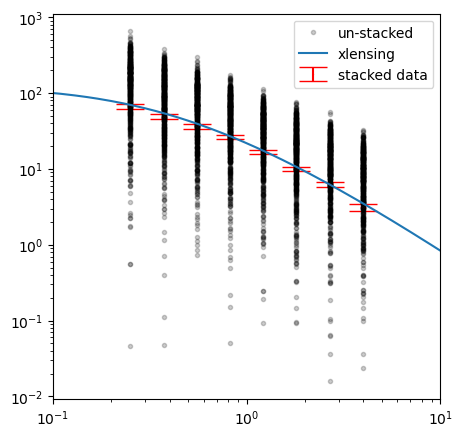

In [58]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas_stack),color='red',s=10)
plt.errorbar(radii,np.array(sigmas_stack),
             yerr=np.sqrt(np.diag(sigmas_cov_stack)),
             fmt='.',color='red',markersize=.1,capsize=10,label='stacked data')

for index, single in enumerate(singles):
    if index==0:
        plt.plot(radii,single[0],'k.',alpha=.2,label='un-stacked')
    else:
        plt.plot(radii,single[0],'k.',alpha=.2)
plt.xlim([.1,1e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')
radii_mpc = np.linspace(0.01,10,1000)

plt.plot(radii_mpc,delta_sigma_xlensing,label='xlensing')
plt.legend()

In [260]:
def model_wrapper(param_dict):
    delta_sigma_model=NFW_shear(
        10**param_dict['logMhalo'],
        param_dict['conc'],
        zhalo,
        1.,
        0.,
        0.,
        radii
    )['NFW Signal']*cosmo.h

    return delta_sigma_model

def loglike(param_dict):
    model=model_wrapper(param_dict)
    data=sigmas_stack
    return multivariate_normal.logpdf(model-data,cov=sigmas_cov_stack)
    

In [261]:
sampler = Sampler(prior, loglike, n_live=4000,pool=15)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 19     | 1        | 4        | 78960    | N/A    | 22132 | -18.72   


np.True_

In [262]:
points, log_w, log_l = sampler.posterior()
mlo, mmd, mhi = np.percentile(points[:,0],[16,50,84])
clo, cmd, chi = np.percentile(points[:,1],[16,50,84])

print("Marginalized:")
print(f"logMass: {mmd:.4f} - {mmd-mlo:.4f} + {mhi-mmd:.4f}")
print(f"conc: {cmd:.4f} - {cmd-clo:.4f} + {chi-cmd:.4f}")

Marginalized:
logMass: 13.6256 - 0.4838 + 0.0223
conc: 2.4644 - 0.2573 + 2.9684


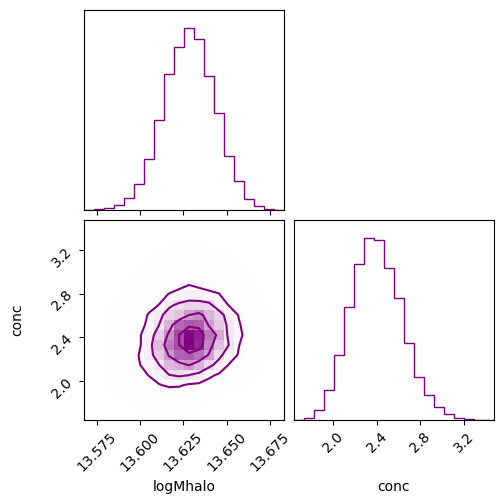

In [263]:
figure = corner.corner(
    points, weights=np.exp(log_w), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.9999, len(prior.keys)))


corner.overplot_lines(figure, [14,5], color="black", linestyle="--")

In [264]:
curve_samples = []
for index in tqdm.tqdm(range(300)):
    point = points[np.random.randint(0,len(points)-1)]
    xlensing_res=xlensing.model.NFW_shear(10**point[0],point[1],zhalo,1.,0.,0.,radii_mpc)
    delta_sigma_data = xlensing_res['NFW Signal']
    curve_samples += [delta_sigma_data]

100%|█████████████████████████████████████████████████████████████████████████████████| 300/300 [00:19<00:00, 15.41it/s]


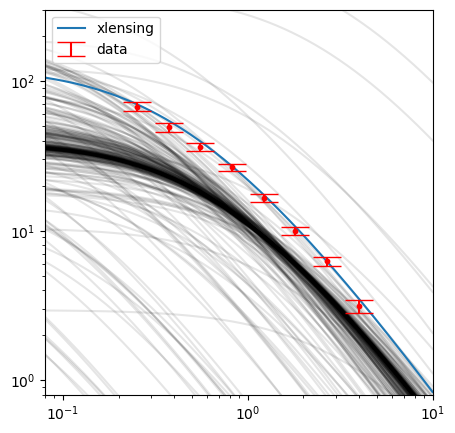

In [265]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas_stack),color='red',s=10,zorder=3)
plt.errorbar(radii,np.array(sigmas_stack),
             yerr=np.sqrt(np.diag(sigmas_cov_stack)),
             fmt='.',color='red',markersize=.1,capsize=10,label='data',zorder=3)
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')

plt.xlim([.8e-1,1e1])
plt.ylim([8e-1,3e2])
for curve_sample in curve_samples:
    plt.plot(radii_mpc,curve_sample,alpha=.1,color='black')


plt.plot(radii_mpc,delta_sigma_true,label='xlensing')
plt.legend()

In [65]:
len(singles[0])

4

In [66]:
def loglike(param_dict):
    model=model_wrapper(param_dict)
    data=sigmas_single
    return multivariate_normal.logpdf(model-data,cov=sigmas_cov_single)


In [67]:


# Assuming your data:
# cov_matrices: shape (1000, 8, 8)
# data_vectors: shape (1000, 8)

def log_gaussian(data_vectors, cov_matrices):
    """
    Vectorized computation of sum of log likelihoods
    """
    n = len(data_vectors)
    k = data_vectors.shape[1]
    
    # Compute log determinant and inverse for each covariance matrix
    log_dets = np.zeros(n)
    inv_covs = np.zeros_like(cov_matrices)
    
    for i in range(n):
        # Cholesky decomposition (more stable than direct inversion)
        try:
            L = np.linalg.cholesky(cov_matrices[i])
            log_dets[i] = 2 * np.sum(np.log(np.diag(L)))
            inv_covs[i] = np.linalg.solve(cov_matrices[i], np.eye(k))
        except np.linalg.LinAlgError:
            # Handle non-positive definite matrices
            return -np.inf
    
    # Compute Mahalanobis distances
    # Center the data
    centered = data_vectors  # Assuming mean is zero, otherwise subtract mean
    
    # Compute quadratic form: x^T Σ^{-1} x
    quad_forms = np.einsum('ij,ijk,ik->i', centered, inv_covs, centered)
    
    # Log likelihood formula: -k/2 * ln(2π) - 1/2 * ln|Σ| - 1/2 * (x^T Σ^{-1} x)
    log_likelihoods = -0.5 * k * np.log(2 * np.pi) - 0.5 * log_dets - 0.5 * quad_forms
    
    return np.sum(log_likelihoods)

In [85]:
def cholog_gaussian(data_vectors, cov_matrices):
    """
    Optimized using Cholesky decomposition for better numerical stability
    """
    n, k = data_vectors.shape
    total_log_lik = 0
    log_2pi = np.log(2 * np.pi)
    
    for i in range(n):
        # Cholesky decomposition
        try:
            L = np.linalg.cholesky(cov_matrices[i])
            # Solve L * y = x (forward substitution)
            y = np.linalg.solve(L, data_vectors[i])
            # Compute quadratic form
            quad_form = np.sum(y**2)
            # Log determinant
            log_det = 2 * np.sum(np.log(np.diag(L)))
            
            # Log likelihood
            log_lik = -0.5 * (k * log_2pi + log_det + quad_form)
            total_log_lik += log_lik
            
        except np.linalg.LinAlgError:
            return -np.inf
    
    return total_log_lik

In [84]:
data_vectors=[]
cov_matrices=[]
for n in tqdm.tqdm(range(10)):
    data_vectors+=[np.load(f"data/single_sigmas_{n}.npy",allow_pickle=True)]
    cov_matrices+=[np.load(f"data/single_sigmas_cov_{n}.npy",allow_pickle=True)]

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 569.25it/s]


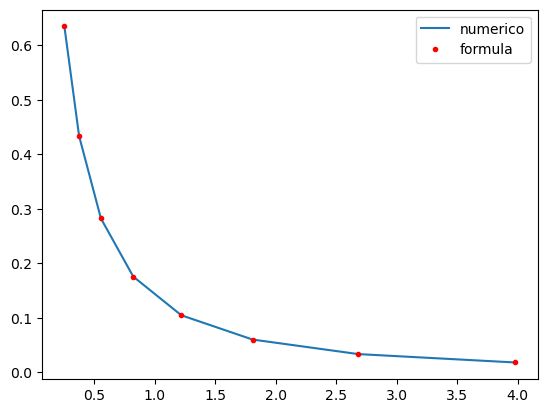

In [342]:
def SigX2(x):
    result = np.zeros_like(x)
    lesser = x<1
    equal = x==1
    greater = x>1
    result[equal]=1/3
    result[lesser] =(1 - 2/np.sqrt(1-x[lesser]**2)*np.arctanh(np.sqrt((1-x[lesser])/(1+x[lesser]))))/(x[lesser]**2-1) 
    result[greater]=(1 - 2/np.sqrt(x[greater] **2-1)*np.arctan(np.sqrt((x[greater]-1)/(1+x[greater]))))/(x[greater]**2-1) 
    return result
def SigBar(x):
    result = np.zeros_like(x)
    lesser = x<1
    equal = x==1
    greater = x>1
    result[equal]  =2.*(1+np.log(0.5))
    result[lesser] = 2/x[lesser]**2 * ( 2./np.sqrt(1-x[lesser]**2)*np.arctanh(np.sqrt((1-x[lesser])/(1+x[lesser]))) + np.log(x[lesser]/2) )
    result[greater]= 2/x[greater]**2 * ( 2./np.sqrt(x[greater]**2-1)*np.arctan(np.sqrt((x[greater]-1)/(1+x[greater]))) + np.log(x[greater]/2) )
    return result   


rs= r_vir_m(Z,M200)/C200

#versao 1
sigbarx =  np.array([(2/(r*r))*integrate.quad(
  lambda x: x*SigX2(x/rs),
  0,
  r,

  full_output=1
)[0]  for r in radii])

#versao 2 
sigbarx2 = [SigBar(r/rs) for r in radii]

plt.plot(radii,sigbarx,label='numerico')
plt.plot(radii,sigbarx2,'r.',label='formula')
plt.legend()

In [339]:
2/x**2 * ( 2./np.sqrt(1-x[lesser]**2)*np.arctanh(np.sqrt((1-x[lesser])/(1+x[lesser]))) + np.log(x[lesser]/2) )

array([0.63470535, 0.28821396, 0.13087536, 0.05942932, 0.02698632,
       0.01225424, 0.00556454, 0.00252681])

In [340]:
x = X

result = np.zeros_like(x)
lesser = x<1
equal = x==1
greater = x>1
result[equal]  =2.*(1+np.log(0.5))


In [343]:
#scale radius
rs= r_vir_m(Z,M200)/C200

#dimensional factors
fact =  2*rs*NFW_delta_c(C200)*cosmo.rhoM(Z)

#adimensional radii
xi = SIGMA/rs
X = radii/rs

sigx= SigX2(X)
sigbarx = SigBar(X)

#shear due to the baryonic mass of the central galaxy
signal_BCG = M0/(np.pi*radii**2)/1e12

#shear due to correctly centered galaxy systems
signal_NFW_centre = fact*(sigbarx-sigx)/1e12

#shear due to miscentered galaxy systems
signal_NFW_miscc  = fact*Delta_Sigma_NFW_off_x(X, xi).reshape(radii.shape)/1e12

#shear due to the large scale structure of the universe
signal_2ht = Delta_Sigma_l(Z, radii)*Bias(Z, M200)/1e12

signal_total = signal_BCG + PCC*signal_NFW_centre + (1 - PCC)*signal_NFW_miscc + signal_2ht
signal_total

array([70.36011542, 54.83728661, 40.13393217, 27.68341218, 18.16146148,
       11.49255242,  7.14653535,  4.46280062])

In [348]:
np.outer(radii,1/rs)

array([[ 0.96362147],
       [ 1.42999671],
       [ 2.12208907],
       [ 3.14914154],
       [ 4.6732687 ],
       [ 6.93504564],
       [10.29148144],
       [15.27237103]])

In [487]:
from xlensing.model import SigX, Delta_Sigma_NFW_off_x, Bias, r_vir_m, NFW_delta_c, Delta_Sigma_l, Sigma_l
from xlensing import cosmo

def NFW_shear(M200, C200, Z, PCC, SIGMA, M0, radii):
    """
    NFW MODEL:
    
    - M200: mass in Msun
    - C200: concentration
    - Z: redshift
    - PCC: fraction of miscentered signal
    - SIGMA: characteristic miscentering
    - M0: baryonic mass of central gaelaxy
    - radii: a collection of radii at which we calculate the model (mpc)
    
    RETURNS:
    
    A dict containing each part of the signal in Msun/pc2. See below.
    """
    
    #scale radius
    rs= r_vir_m(Z,M200)/C200
    
    #dimensional factors
    fact =  2*rs*NFW_delta_c(C200)*cosmo.rhoM(Z)
    
    #adimensional radii
    xi = SIGMA/rs
    X = radii/rs
    
    sigx= SigX2(X)
    sigbarx = SigBar(X)
    
    #shear due to the baryonic mass of the central galaxy
    signal_BCG = M0/(np.pi*radii**2)/1e12
    
    #shear due to correctly centered galaxy systems
    signal_NFW_centre = fact*(sigbarx-sigx)/1e12
    
    #shear due to miscentered galaxy systems
    signal_NFW_miscc  = fact*Delta_Sigma_NFW_off_x(X, xi).reshape(radii.shape)/1e12

    #shear due to the large scale structure of the universe
    signal_2ht = Delta_Sigma_l(Z, radii)*Bias(Z, M200)/1e12
    
    signal_total = signal_BCG + PCC*signal_NFW_centre + (1 - PCC)*signal_NFW_miscc + signal_2ht
    
    signal = {'Signal': signal_total,
              'BCG Signal': signal_BCG,
              'NFW Signal': signal_NFW_centre,
              'Miscentered Signal': signal_NFW_miscc,
              'Two-halo term': signal_2ht,
              'radii': radii
             }

    return signal
NFW_shear(
    M200=1e14,
    C200=5,
    Z=0.3,
    PCC=1.0,
    SIGMA=0.,
    M0=0,
    radii=radii,
)['Signal']

array([70.36011542, 54.83728661, 40.13393217, 27.68341218, 18.16146148,
       11.49255242,  7.14653535,  4.46280062])

In [345]:
%%timeit
for i in range(1000):
    NFW_shear(
        M200=1e14,
        C200=5,
        Z=0.3,
        PCC=1.0,
        SIGMA=0.,
        M0=0,
        radii=radii,
    )['Signal']

5.73 s ± 51.4 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [403]:
from scipy.interpolate import RectBivariateSpline as BSpline
from astropy.table import Table
resources = "/home/andre/github/xlensing/xlensing"
MscRadii = Table.read(resources+"/misc_NFW_radii.fits")
Profs = Table.read(resources+"/misc_NFW_profiles.fits")
print("Lookup tables loaded!")
Delta_Sigma_NFW_off_x = BSpline(MscRadii['col0'],Profs['col0'],Profs['col1'].T,s=0)

Lookup tables loaded!


In [465]:
Z = np.array([0.3,0.3,0.3,0.3])
M200 = np.array([1e14,1e14,1e14,1e14])
C200 = np.array([5.,5.,5.,5.])
SIGMA = np.array([0.4,0.5,0.6,0.2])
# Z = np.array([0.3,])
# M200 = np.array([1e14,])
# C200 = np.array([5.,])
fact =  2*rs*NFW_delta_c(C200)*cosmo.rhoM(Z)
rs = r_vir_m(Z,M200)/C200
xi = SIGMA/rs
X = np.outer(radii,1/rs)


sigx= SigX2(X)
sigbarx = SigBar(X)
signal_NFW_centre = fact*(sigbarx-sigx)/1e12
signal_NFW_miscc  = fact*Delta_Sigma_NFW_off_x_v(X[:,xi.argsort()],xi[xi.argsort()])[:,xi.argsort().argsort()]/1e12
signal_2ht = Delta_Sigma_l(Z, radii)*Bias(Z, M200)/1e12


In [496]:

Bias(Z, M200) @ Delta_Sigma_l(Z, radii) /1e12

ValueError: operands could not be broadcast together with shapes (4,) (8,) 

In [492]:
Delta_Sigma_l(Z[:,np.newaxis],radii)

array([[ 6.41570479,  7.85026592,  9.42498619, 11.06985903, 12.67383567,
        14.08321332, 15.10947155, 15.55371787],
       [ 6.41570479,  7.85026592,  9.42498619, 11.06985903, 12.67383567,
        14.08321332, 15.10947155, 15.55371787],
       [ 6.41570479,  7.85026592,  9.42498619, 11.06985903, 12.67383567,
        14.08321332, 15.10947155, 15.55371787],
       [ 6.41570479,  7.85026592,  9.42498619, 11.06985903, 12.67383567,
        14.08321332, 15.10947155, 15.55371787]])

In [464]:
Delta_Sigma_NFW_off_x(X[:,0],xi[0])

array([[0.01214612],
       [0.02387006],
       [0.0416291 ],
       [0.05764938],
       [0.05649544],
       [0.04039412],
       [0.02481073],
       [0.01424999]])

In [359]:
def NFW_delta_c(conc):
    return (cosmo.cluster_overdensity/3.)*((conc**3)/(np.log(1.+conc)-conc/(1.+conc)))

fact =  2*rs*NFW_delta_c(C200)*cosmo.rhoM(Z)

In [368]:
fact * (sigbarx-sigx)/1e12

array([[69.97065485, 69.97065485, 76.42737494],
       [54.36074208, 54.36074208, 59.94553241],
       [39.56179542, 39.56179542, 44.05102105],
       [27.01142465, 27.01142465, 30.35448266],
       [17.39210575, 17.39210575, 19.70674436],
       [10.63764147, 10.63764147, 12.13942314],
       [ 6.22932617,  6.22932617,  7.15124098],
       [ 3.5186238 ,  3.5186238 ,  4.05923278]])

In [363]:
fact[0]*(sigbarx-sigx)[0]

array([6.99706548e+13, 6.99706548e+13, 7.22435755e+13])

In [381]:
fact*(sigbarx-sigx)/1e12

array([[69.97065485, 69.97065485, 76.42737494],
       [54.36074208, 54.36074208, 59.94553241],
       [39.56179542, 39.56179542, 44.05102105],
       [27.01142465, 27.01142465, 30.35448266],
       [17.39210575, 17.39210575, 19.70674436],
       [10.63764147, 10.63764147, 12.13942314],
       [ 6.22932617,  6.22932617,  7.15124098],
       [ 3.5186238 ,  3.5186238 ,  4.05923278]])

In [380]:
fact[2]*(sigbarx-sigx)[:,2]/1e12

array([76.42737494, 59.94553241, 44.05102105, 30.35448266, 19.70674436,
       12.13942314,  7.15124098,  4.05923278])

In [ ]:
plt.hist((data_vectors - models).flatten(),bins=20);

In [ ]:
def multiloglike(param_dict):
    models=model_wrapper(param_dict,zees)
    #models = np.tile(model,10).reshape(-1,len(model))
    return cholog_gaussian(data_vectors-models, cov_matrices)




In [ ]:
param_dict = {
    'logMhalo':14.,
    'conc': 5.,
}

In [ ]:
%%timeit
multiloglike(param_dict)

In [ ]:
sampler = Sampler(prior, multiloglike, n_live=1000,pool=15)
sampler.run(verbose=True)


In [ ]:
points, log_w, log_l = sampler.posterior()
mlo, mmd, mhi = np.percentile(points[:,0],[16,50,84])
clo, cmd, chi = np.percentile(points[:,1],[16,50,84])

print("Marginalized:")
print(f"logMass: {mmd:.4f} - {mmd-mlo:.4f} + {mhi-mmd:.4f}")
print(f"conc: {cmd:.4f} - {cmd-clo:.4f} + {chi-cmd:.4f}")

In [ ]:
import corner
figure = corner.corner(
    points, weights=np.exp(log_w), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.9999, len(prior.keys)))


corner.overplot_lines(figure, [14,5], color="black", linestyle="--")

In [ ]:
allchains=np.vstack([single_fit[0] for single_fit in single_fits])

In [ ]:
allweights=np.hstack([single_fit[1] for single_fit in single_fits])

In [ ]:
figure = corner.corner(
    allchains, weights=np.exp(allweights), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.9999, len(prior.keys)))
corner.overplot_lines(figure, [14,5], color="black", linestyle="--")

In [ ]:

mlo, mmd, mhi = np.percentile(allchains[:,0],[16,50,84])
clo, cmd, chi = np.percentile(allchains[:,1],[16,50,84])

print("Marginalized:")
print(f"logMass: {mmd:.4f} - {mmd-mlo:.4f} + {mhi-mmd:.4f}")
print(f"conc: {cmd:.4f} - {cmd-clo:.4f} + {chi-cmd:.4f}")

In [ ]:
singles[0]    
    

In [ ]:

def weighted_quantile(values, quantiles, sample_weight=None, 
                      values_sorted=False, old_style=False):
    """ Very close to numpy.percentile, but supports weights.
    NOTE: quantiles should be in [0, 1]!
    :param values: numpy.array with data
    :param quantiles: array-like with many quantiles needed
    :param sample_weight: array-like of the same length as `array`
    :param values_sorted: bool, if True, then will avoid sorting of
        initial array
    :param old_style: if True, will correct output to be consistent
        with numpy.percentile.
    :return: numpy.array with computed quantiles.
    """
    values = np.array(values)
    quantiles = np.array(quantiles)
    if sample_weight is None:
        sample_weight = np.ones(len(values))
    sample_weight = np.array(sample_weight)
    assert np.all(quantiles >= 0) and np.all(quantiles <= 1), \
        'quantiles should be in [0, 1]'

    if not values_sorted:
        sorter = np.argsort(values)
        values = values[sorter]
        sample_weight = sample_weight[sorter]

    weighted_quantiles = np.cumsum(sample_weight) - 0.5 * sample_weight
    if old_style:
        # To be convenient with numpy.percentile
        weighted_quantiles -= weighted_quantiles[0]
        weighted_quantiles /= weighted_quantiles[-1]
    else:
        weighted_quantiles /= np.sum(sample_weight)
    return np.interp(quantiles, weighted_quantiles, values)